# Where should a café brand open next in Hanoi?
### A data-driven site-selection study across Hanoi's 30 former districts

**Author:** Chi Nguyen · **Data:** OpenStreetMap, Wikipedia, mogi.vn · **Updated:** October 2026

---

### Executive summary

**Recommendation: open in Thanh Xuân, with Đống Đa as the lower-risk alternative. Confirm with a one-day field count first.**

| | |
|---|---|
| **Thanh Xuân** | Dense (32k residents/km²) and beside the core office belt, yet it has **31 mapped cafés where its demand predicts ~123**. Chain cafés tell the same story: 6 against ~15 expected. Land is ~20 % cheaper than in the other inner districts. It ranks **#1 in 80 %** of 10,000 random scoring weightings and **top 3 in 90 %**. |
| **Đống Đa** | The balanced choice: high demand, a moderate shortfall, and the best value for land in the core. It is top 3 in 76 % of weightings and **#1 if the supply-gap signal is ignored**, so it does not depend on the least certain estimate. |
| **Avoid** | **Hoàn Kiếm** has 2 % of Hanoi's residents, 28 % of its cafés and land prices 2.7–3.5× the other core districts. **Tây Hồ** is priced ~2.8× what its footfall implies. |

**How I got there:** I validated four public sources (official and OSM areas agree within 0.4 % median error) and
measured a mapping bias in OpenStreetMap, then designed around it. A PCA demand index captures 93 % of the variation across six footfall
drivers. A negative-binomial model with a saturation term (preferred on AIC and leave-one-out error) estimates expected
café supply. A three-segment clustering is confirmed by two algorithms and bootstrap stability. The ranking comes from screening and scoring,
stress-tested with Monte-Carlo weights. A 500 m grid model then turns the district choice into **10 specific blocks to scout**.

**Biggest risk:** OpenStreetMap misses many small independent cafés outside the centre, so Thanh Xuân's shortfall may be
overstated. It is cross-checked with chain-only data (same result), but a field count of the top 5 blocks is the go/no-go test.

*Figures are in [`reports/figures`](../reports/figures). The interactive block map is in [`reports/micro_location_map.html`](../reports/micro_location_map.html).*

## 1. The business problem

A mid-range café chain (think *Highlands*, *Phúc Long*, *Cộng*) wants to open its next Hanoi location.
Rent is the largest fixed cost, and the market is already crowded, so the question is not *"where are people?"* but:

> **Where is demand high, competition low relative to that demand, and land still affordable?**

**Decision this analysis supports:** a ranked shortlist of districts, then specific 500 m blocks to scout inside the winner.

**How the answer is built**

| Step | Question | Method |
|---|---|---|
| 1 | Can the data be trusted? | Source validation, join coverage, mapping-bias test |
| 2 | Where is café demand? | Demand index from 6 footfall drivers (PCA) |
| 3 | Where is supply short of demand? | Negative-binomial model of café counts → expected vs actual |
| 4 | What kinds of district exist? | K-means + Ward clustering, silhouette & bootstrap stability |
| 5 | Which district wins? | Screen → weighted score → 10,000-draw weight sensitivity |
| 6 | Where exactly inside it? | 500 m grid, cell-level supply-gap model |

**Hypotheses going in**
- H1. Café supply rises with footfall drivers (offices, schools, transit, retail, tourism), but *saturates* in the old core.
- H2. Land price is explained mostly by the same drivers, so some districts will be cheap *relative to* their demand.
- H3. The best opportunity is not the busiest district (Hoàn Kiếm), but a dense inner district with a thin café supply.

In [1]:
import sys, json, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

from common import PROCESSED, ROOT
import viz
from viz import titles, label_points, save, SERIES, CONTEXT, HIGHLIGHT, INK_2, MUTED

viz.apply_style()
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(42)

df = pd.read_csv(PROCESSED / "district_features.csv")
pois = pd.read_csv(PROCESSED / "pois.csv")
grid = pd.read_csv(PROCESSED / "grid_500m.csv")
DEMAND = ["office", "education", "tourism", "retail", "transit"]
print(f"{len(df)} districts · {len(pois):,} points of interest · {len(grid):,} urban grid cells")

30 districts · 15,484 points of interest · 874 urban grid cells


## 2. Data and data quality

| Source | What it gives | Unit | Notes |
|---|---|---|---|
| Wikipedia *Hanoi*, revision of 29 May 2025 (pinned) | Area, population | 30 former districts | Last revision before the July 2025 reform |
| mogi.vn/gia-nha-dat | Average asking price per m² | 27 districts | Snapshot Oct 2026; asking, not transacted, prices |
| OpenStreetMap (as of 1 Jan 2025) | District boundaries | 30 polygons | Historical query: districts were abolished 1 Jul 2025 |
| OpenStreetMap (current) | 15k points of interest in 8 categories | Points | Cafés, F&B, offices, schools, hotels, shops, transit |

The full pipeline is `src/fetch_data.py → src/build_dataset.py`; raw responses are cached so results reproduce offline.

### 2.1 Validation checks

In [2]:
area_err = (df.area_km2_osm / df.area_km2_wiki - 1).abs()
checks = pd.DataFrame({
    "check": ["Districts with population & area", "Districts with an OSM boundary",
              "Districts with a land price", "OSM vs official area, median abs. error",
              "OSM vs official area, worst abs. error", "Population total (millions)"],
    "result": [f"{df.population.notna().sum()}/30", f"{df.area_km2_osm.notna().sum()}/30",
               f"{df.price_mvnd_m2.notna().sum()}/30", f"{area_err.median():.1%}",
               f"{area_err.max():.1%} ({df.loc[area_err.idxmax(), 'district']})",
               f"{df.population.sum() / 1e6:.2f}"],
})
checks

,check,result
0,Districts with population & area,30/30
1,Districts with an OSM boundary,30/30
2,Districts with a land price,27/30
3,"OSM vs official area, median abs. error",0.4%
4,"OSM vs official area, worst abs. error",2.1% (Quốc Oai)
5,Population total (millions),8.44


Boundaries derived independently from OSM match the official areas to within ~1 %, which confirms that the historical
district polygons, the population table and the price table all describe **the same geography**.
The three districts without a price (Mỹ Đức, Phú Xuyên, Ứng Hòa) are remote rural districts. They are kept for the city-wide
segmentation and excluded from scoring, where they would fail the density screen anyway.

### 2.2 The bias that matters: OSM under-maps small independent cafés outside the centre

OpenStreetMap is volunteer-built. Branded chains are mapped consistently (brand tags are curated), whereas a family-run
*cà phê* in Hoàng Mai is far less likely to be mapped than one on a tourist street in Hoàn Kiếm.
If that is true, the **chain share of mapped cafés should fall as the café map gets denser**.

Urban districts: Spearman ρ(chain share, mapped café density) = -0.68 (p = 0.015)


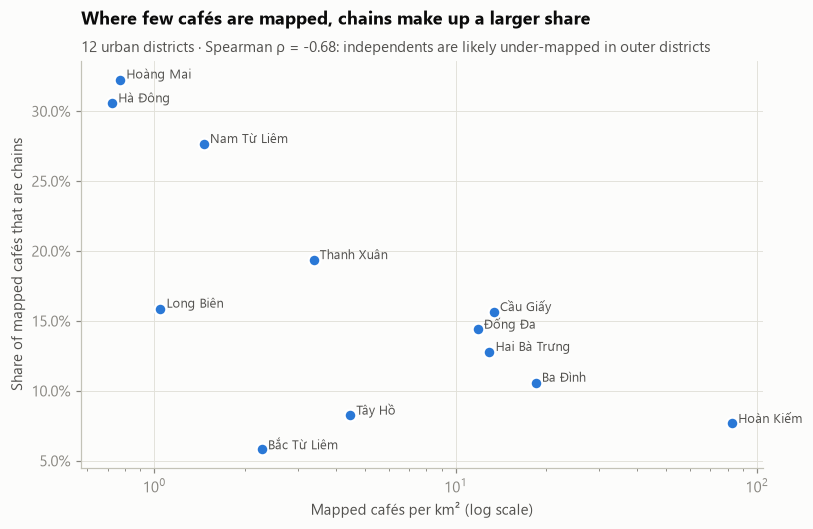

In [3]:
urban = df[df.district_type == "urban"].copy()
rho, p = stats.spearmanr(urban.cafe_chain_share, urban.cafe_per_km2)
print(f"Urban districts: Spearman ρ(chain share, mapped café density) = {rho:.2f} (p = {p:.3f})")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(urban.cafe_per_km2, urban.cafe_chain_share, s=60, color=HIGHLIGHT, edgecolor="white", linewidth=1.5, zorder=3)
label_points(ax, urban.cafe_per_km2, urban.cafe_chain_share, urban.district)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Mapped cafés per km² (log scale)")
ax.set_ylabel("Share of mapped cafés that are chains")
titles(ax, "Where few cafés are mapped, chains make up a larger share",
       f"12 urban districts · Spearman ρ = {rho:.2f}: independents are likely under-mapped in outer districts")
save(fig, "fig01_mapping_bias")
plt.show()

**Why this changes the method:** raw café counts would make outer districts look emptier than they are. Three safeguards
are built in:

1. Supply is always judged **relative to demand drivers that also come from OSM**, so district-level mapping
   completeness partly cancels out.
2. Every supply result is **re-run on chain cafés only**, the direct competitors of a chain and the most evenly mapped
   subset. Conclusions are accepted only if both measures agree.
3. The shortlist is treated as *where to send scouts*, not as a final verdict (see §8).

## 3. Market landscape: cafés are far more concentrated than people

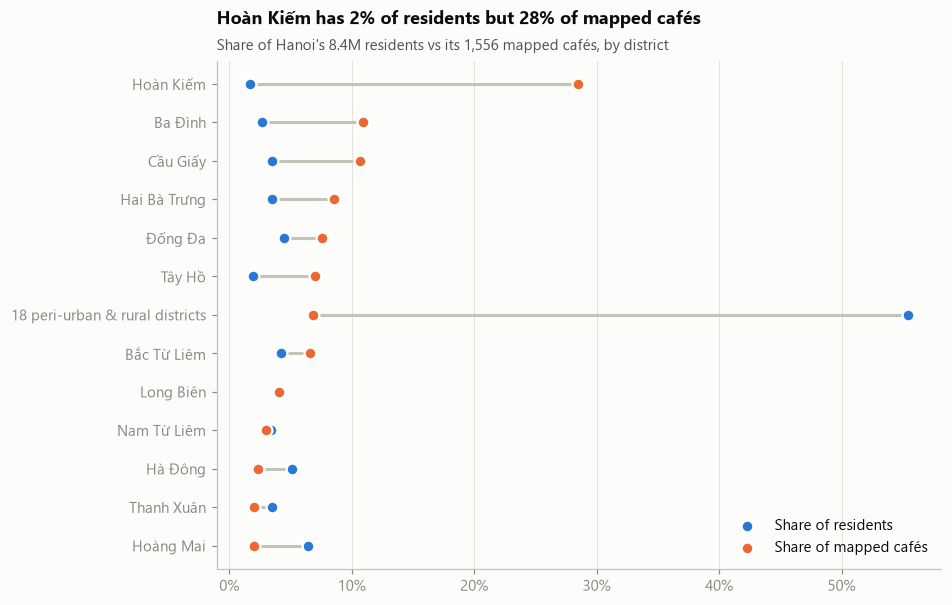

12 urban districts: 45% of residents, 93% of cafés
Hoàn Kiếm: 1.7% of residents, 28.5% of cafés


In [4]:
tot_pop, tot_cafe = df.population.sum(), df.n_cafe.sum()
land = (df.assign(group=np.where(df.district_type == "urban", df.district, "18 peri-urban & rural districts"))
          .groupby("group")[["population", "n_cafe"]].sum())
land["share_pop"] = land.population / tot_pop
land["share_cafe"] = land.n_cafe / tot_cafe
land = land.sort_values("share_cafe")

fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(land))
ax.hlines(y, land.share_pop, land.share_cafe, color=CONTEXT, linewidth=2, zorder=1)
ax.scatter(land.share_pop, y, s=60, color=SERIES[0], label="Share of residents", zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter(land.share_cafe, y, s=60, color=SERIES[1], label="Share of mapped cafés", zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(y, land.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
hk = land.loc["Hoàn Kiếm"]
titles(ax, f"Hoàn Kiếm has {hk.share_pop:.0%} of residents but {hk.share_cafe:.0%} of mapped cafés",
       f"Share of Hanoi's {tot_pop/1e6:.1f}M residents vs its {tot_cafe:,} mapped cafés, by district")
save(fig, "fig02_concentration")
plt.show()

core_share = df.loc[df.district_type == "urban", "n_cafe"].sum() / tot_cafe
print(f"12 urban districts: {df.loc[df.district_type=='urban','population'].sum()/tot_pop:.0%} of residents, {core_share:.0%} of cafés")
print(f"Hoàn Kiếm: {hk.share_pop:.1%} of residents, {hk.share_cafe:.1%} of cafés")

Residents are not the only customers: offices, universities, hotels and transit hubs pull daytime footfall into the core.
To compare districts fairly we need a single measure of **demand** that captures all of these drivers.

## 4. A demand index from six footfall drivers

Each driver is expressed per km² and log-transformed (the counts are heavily right-skewed). Because the drivers are strongly
correlated, PCA combines them into one index without double-counting.

In [5]:
demand_cols = [f"{c}_per_km2" for c in DEMAND] + ["density_per_km2"]
X = np.log1p(df[demand_cols])
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)
sign = np.sign(pca.components_[0].sum())
df["demand_index"] = pca.transform(Z)[:, 0] * sign

print(f"PC1 explains {pca.explained_variance_ratio_[0]:.1%} of the variance across the six drivers")
pd.DataFrame({"loading on PC1": pca.components_[0] * sign},
             index=["Offices", "Education", "Tourism", "Retail", "Transit stops", "Residential density"]).T

PC1 explains 92.6% of the variance across the six drivers


,Offices,Education,Tourism,Retail,Transit stops,Residential density
loading on PC1,0.42,0.42,0.36,0.42,0.42,0.41


PC1 alone explains ~93 % of the variation and every driver loads almost equally (0.36–0.42). In other words, Hanoi's
footfall drivers move together: there is essentially **one dimension of urban intensity**. That justifies a single index,
and it also warns that we cannot separate "office demand" from "student demand" at district level with this data.
The grid analysis in §7 works at a finer level, where they do separate.

## 5. Supply vs demand: where are cafés missing?

**Model.** Café counts are over-dispersed (variance ≫ mean), so I use a **negative-binomial regression** with log(area)
as an offset, which models café *density* as a function of demand:

$$\log E[\text{cafés}_i] = \log(\text{area}_i) + \beta_0 + \beta_1\,D_i + \beta_2\,D_i^2$$

The quadratic term tests H1 (saturation). Model choice is made on AIC and leave-one-out prediction error, not on fit alone.

In [6]:
df["log_area"] = np.log(df.area_km2_wiki)
forms = {"linear": "n_cafe ~ demand_index", "quadratic": "n_cafe ~ demand_index + I(demand_index**2)"}

def loocv_rmse(formula, target="n_cafe"):
    errs = []
    for i in df.index:
        train = df.drop(i)
        m = smf.negativebinomial(formula.replace("n_cafe", target), train, offset=train.log_area).fit(disp=0)
        pred = m.predict(df.loc[[i]], offset=df.loc[[i], "log_area"]).iloc[0]
        errs.append(np.log1p(pred) - np.log1p(df.loc[i, target]))
    return np.sqrt(np.mean(np.square(errs)))

rows = []
for name, f in forms.items():
    m = smf.negativebinomial(f, df, offset=df.log_area).fit(disp=0)
    rows.append({"model": name, "AIC": m.aic, "LOOCV RMSE (log cafés)": loocv_rmse(f), "pseudo R²": m.prsquared})
pd.DataFrame(rows).set_index("model")

,AIC,LOOCV RMSE (log cafés),pseudo R²
model,,,
linear,247.49,1.10,0.20
quadratic,241.39,1.01,0.23


In [7]:
gap_model = smf.negativebinomial(forms["quadratic"], df, offset=df.log_area).fit(disp=0)
print(gap_model.summary().tables[1])
df["expected_cafe"] = gap_model.predict(df, offset=df.log_area)
# Headroom > 0: fewer cafés than demand predicts. +1 smoothing keeps rural zeros finite.
df["headroom"] = np.log((df.expected_cafe + 1) / (df.n_cafe + 1))

# Robustness: same model on chain cafés only (direct competitors, most evenly mapped).
chain_model = smf.negativebinomial(forms["quadratic"].replace("n_cafe", "n_cafe_chain"), df, offset=df.log_area).fit(disp=0)
df["expected_chain"] = chain_model.predict(df, offset=df.log_area)
df["headroom_chain"] = np.log((df.expected_chain + 1) / (df.n_cafe_chain + 1))

urban = df[df.district_type == "urban"].copy()
r_all = stats.spearmanr(df.expected_cafe, df.n_cafe)[0]
r_rob = stats.spearmanr(urban.headroom, urban.headroom_chain)
print(f"\nRank correlation, expected vs actual cafés (30 districts): {r_all:.2f}")
print(f"Agreement of headroom ranks, all cafés vs chains only (12 urban): ρ = {r_rob[0]:.2f}, p = {r_rob[1]:.3f}")

                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -0.7867      0.240     -3.275      0.001      -1.257      -0.316
demand_index             1.3628      0.115     11.827      0.000       1.137       1.589
I(demand_index ** 2)    -0.0999      0.032     -3.165      0.002      -0.162      -0.038
alpha                    0.7909      0.235      3.366      0.001       0.330       1.251

Rank correlation, expected vs actual cafés (30 districts): 0.88
Agreement of headroom ranks, all cafés vs chains only (12 urban): ρ = 0.67, p = 0.017


**Reading the model**
- The quadratic model wins on both AIC and out-of-sample error, and its negative squared term is significant: **H1 is supported**.
  Café density rises steeply with demand, then flattens in the most intense districts. A linear model would wrongly
  call Hoàn Kiếm "under-supplied" because it extrapolates the steep part of the curve.
- Expected and actual counts rank-correlate strongly across the 30 districts, so demand alone explains most of where cafés are.
  **The residual (headroom) is the opportunity signal.**
- The all-café and chain-only headroom ranks agree moderately-to-strongly in the urban districts (ρ = 0.67), so the signal is unlikely to be an artefact
  of independents being under-mapped.

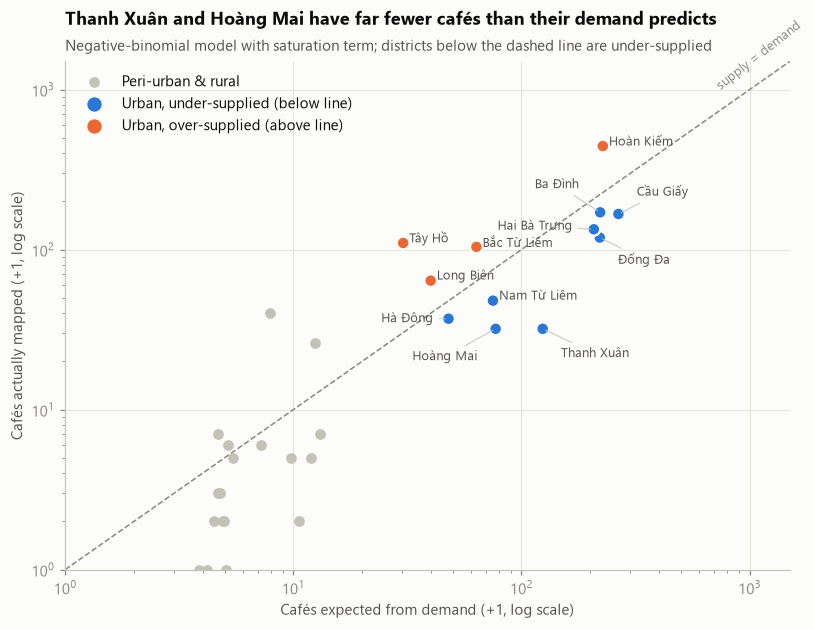

,demand_index,n_cafe,expected_cafe,headroom,n_cafe_chain,expected_chain,headroom_chain
district,,,,,,,
Thanh Xuân,3.26,31,122.90,1.35,6,14.99,0.83
Hoàng Mai,1.14,31,76.08,0.88,10,10.32,0.03
Đống Đa,4.05,118,219.51,0.62,17,24.68,0.36
Cầu Giấy,4.00,166,265.11,0.47,26,29.99,0.14
Nam Từ Liêm,1.32,47,74.02,0.45,13,10.02,-0.24
Hai Bà Trưng,3.89,133,206.67,0.44,17,23.66,0.32
Ba Đình,4.20,170,220.33,0.26,18,24.33,0.29
Hà Đông,0.56,36,46.88,0.26,11,6.37,-0.49
Long Biên,0.27,63,39.02,-0.47,10,5.28,-0.56


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 6))
rural = df[df.district_type != "urban"]
ax.scatter(rural.expected_cafe + 1, rural.n_cafe + 1, s=36, color=CONTEXT, label="Peri-urban & rural", zorder=2)
c = np.where(urban.headroom > 0, SERIES[0], SERIES[1])
ax.scatter(urban.expected_cafe + 1, urban.n_cafe + 1, s=70, color=c, edgecolor="white", linewidth=1.5, zorder=3)
label_points(ax, urban.expected_cafe + 1, urban.n_cafe + 1, urban.district,
             offsets={"Ba Đình": (-14, 14), "Cầu Giấy": (12, 10), "Hai Bà Trưng": (-14, 2), "Đống Đa": (12, -10),
                      "Hoàng Mai": (-12, -14), "Thanh Xuân": (12, -12), "Hà Đông": (-10, 0)})
lim = [1, 1500]
ax.plot(lim, lim, color=MUTED, linewidth=1, linestyle="--", zorder=1)
ax.text(700, 1000, "supply = demand", color=MUTED, fontsize=8.5, rotation=38)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim,
       xlabel="Cafés expected from demand (+1, log scale)", ylabel="Cafés actually mapped (+1, log scale)")
ax.scatter([], [], s=70, color=SERIES[0], label="Urban, under-supplied (below line)")
ax.scatter([], [], s=70, color=SERIES[1], label="Urban, over-supplied (above line)")
ax.legend(loc="upper left")
titles(ax, "Thanh Xuân and Hoàng Mai have far fewer cafés than their demand predicts",
       "Negative-binomial model with saturation term; districts below the dashed line are under-supplied")
save(fig, "fig03_supply_vs_demand")
plt.show()

urban[["district", "demand_index", "n_cafe", "expected_cafe", "headroom", "n_cafe_chain", "expected_chain", "headroom_chain"]] \
    .sort_values("headroom", ascending=False).set_index("district")

## 6. Land price: which districts are cheap *for what they offer*?

Rent is the cost side of the decision. If prices are mostly explained by the same demand drivers (H2), then the
residual tells us which districts are **under-priced relative to their footfall**, which is where a café's margin is best.

log(price) ~ demand index: R² = 0.76, slope = 0.41 (each +1 demand-index point ≈ +51% price), HC3 robust SEs


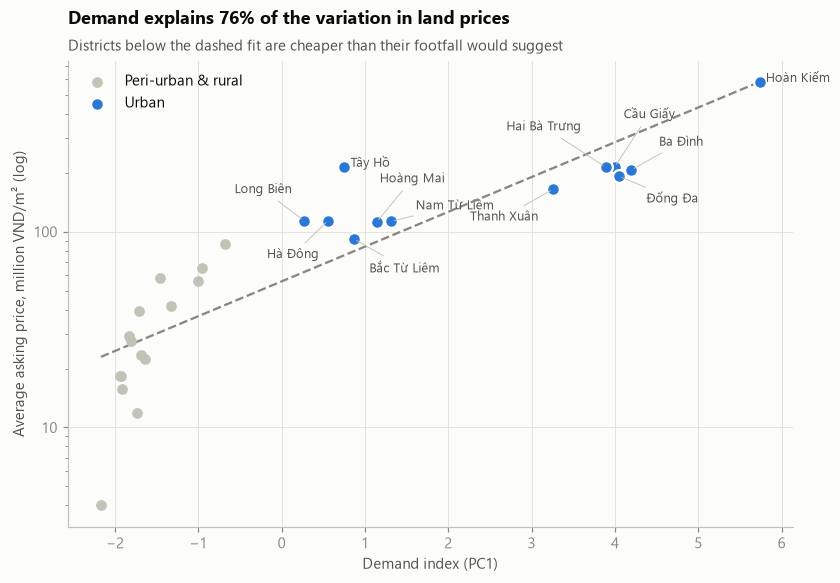

,price_mvnd_m2,price_resid
district,,
Đống Đa,192.0,-4.19e-01
Ba Đình,207.0,-4.05e-01
Cầu Giấy,214.0,-2.89e-01
Thanh Xuân,165.0,-2.49e-01
Hai Bà Trưng,214.0,-2.45e-01
Hoàn Kiếm,579.0,-6.44e-03
Bắc Từ Liêm,91.7,1.43e-01
Nam Từ Liêm,113.0,1.69e-01
Hoàng Mai,112.0,2.31e-01


In [9]:
priced = df.dropna(subset=["price_mvnd_m2"]).copy()
pm = smf.ols("np.log(price_mvnd_m2) ~ demand_index", priced).fit(cov_type="HC3")
priced["price_resid"] = pm.resid
df = df.merge(priced[["key", "price_resid"]], on="key", how="left")
print(f"log(price) ~ demand index: R² = {pm.rsquared:.2f}, slope = {pm.params['demand_index']:.2f} "
      f"(each +1 demand-index point ≈ {np.exp(pm.params['demand_index']) - 1:+.0%} price), HC3 robust SEs")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
xs = np.linspace(priced.demand_index.min(), priced.demand_index.max(), 50)
ax.plot(xs, np.exp(pm.params.Intercept + pm.params.demand_index * xs), color=MUTED, linewidth=1.5, linestyle="--", zorder=1)
is_u = priced.district_type == "urban"
ax.scatter(priced.loc[~is_u, "demand_index"], priced.loc[~is_u, "price_mvnd_m2"], s=36, color=CONTEXT, zorder=2, label="Peri-urban & rural")
ax.scatter(priced.loc[is_u, "demand_index"], priced.loc[is_u, "price_mvnd_m2"], s=70, color=HIGHLIGHT,
           edgecolor="white", linewidth=1.5, zorder=3, label="Urban")
label_points(ax, priced.loc[is_u, "demand_index"], priced.loc[is_u, "price_mvnd_m2"], priced.loc[is_u, "district"],
             offsets={"Hai Bà Trưng": (-16, 22), "Cầu Giấy": (6, 30), "Ba Đình": (18, 14), "Đống Đa": (18, -10),
                      "Thanh Xuân": (-10, -14), "Long Biên": (-8, 16), "Hà Đông": (-6, -18), "Hoàng Mai": (2, 24),
                      "Nam Từ Liêm": (16, 6), "Bắc Từ Liêm": (10, -14)})
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set(xlabel="Demand index (PC1)", ylabel="Average asking price, million VND/m² (log)")
ax.legend(loc="upper left")
titles(ax, f"Demand explains {pm.rsquared:.0%} of the variation in land prices",
       "Districts below the dashed fit are cheaper than their footfall would suggest")
save(fig, "fig04_price_vs_demand")
plt.show()

df.loc[df.district_type == "urban", ["district", "price_mvnd_m2", "price_resid"]].sort_values("price_resid").set_index("district")

**Reading the price model**
- **H2 is supported:** a single demand index explains about three-quarters of the variation in land prices across 27 districts.
- **Tây Hồ carries a large lakeside premium.** It is priced about 2.8× what its footfall implies (residual ≈ +1.0 in logs),
  so it is expensive for what a café would get.
- **Đống Đa and Ba Đình are the best value in the core.** Thanh Xuân sells at 165 M VND/m², about 20 % below its inner-core peers.
- *Caveat:* every inner-core district sits below the line, which partly reflects curvature (prices flatten at the top),
  so residuals are best compared **within** a segment rather than across segments.

## 7. Segmentation: what kinds of district does Hanoi have?

Clustering is used here to **describe** the market, not to pick the winner. Features: residential density plus the
per-km² density of cafés, restaurants and the five demand drivers (all log-transformed and standardised). Price is
left out so the 3 unpriced districts can be included, and is used afterwards to profile the segments.

Choosing *k* is a judgement call, so it is backed by three checks: silhouette score, agreement between two different
algorithms (K-means vs Ward hierarchical), and bootstrap stability.

In [10]:
seg_cols = ["density_per_km2", "cafe_per_km2", "restaurant_per_km2"] + [f"{c}_per_km2" for c in DEMAND]
F = StandardScaler().fit_transform(np.log1p(df[seg_cols]))

def bootstrap_ari(k, n=300):
    ref = KMeans(k, n_init=20, random_state=0).fit(F)
    scores = []
    for _ in range(n):
        idx = RNG.choice(len(F), len(F), replace=True)
        km = KMeans(k, n_init=10, random_state=int(RNG.integers(1e6))).fit(F[idx])
        scores.append(adjusted_rand_score(ref.labels_, km.predict(F)))
    return np.mean(scores)

rows = []
for k in range(2, 7):
    km = KMeans(k, n_init=50, random_state=0).fit(F)
    ward = AgglomerativeClustering(k, linkage="ward").fit(F)
    rows.append({"k": k, "silhouette (K-means)": silhouette_score(F, km.labels_),
                 "silhouette (Ward)": silhouette_score(F, ward.labels_),
                 "K-means vs Ward ARI": adjusted_rand_score(km.labels_, ward.labels_),
                 "bootstrap stability (ARI)": bootstrap_ari(k),
                 "smallest cluster": np.bincount(km.labels_).min()})
pd.DataFrame(rows).set_index("k")

,silhouette (K-means),silhouette (Ward),K-means vs Ward ARI,bootstrap stability (ARI),smallest cluster
k,,,,,
2,0.70,0.70,1.0,0.83,6
3,0.67,0.67,1.0,0.96,6
4,0.67,0.67,1.0,0.95,1
5,0.52,0.52,1.0,0.81,1
6,0.48,0.48,1.0,0.84,1


**Choosing k = 3.** k = 2 scores slightly higher, but it only separates urban from rural, which we already knew.
k = 3 is nearly as good on silhouette, perfectly reproduced by Ward clustering, and stable under resampling.
It also splits the urban districts into two groups that behave very differently. k = 4 only peels off Hoàn Kiếm as a
single-district cluster, and k ≥ 5 degrades on every measure.

In [11]:
km = KMeans(3, n_init=50, random_state=0).fit(F)
df["segment_id"] = km.labels_
# Name segments by their mean demand so labels are stable across runs.
order = df.groupby("segment_id").demand_index.mean().sort_values(ascending=False).index
names = dict(zip(order, ["Inner core", "Urban expansion ring", "Peri-urban & rural"]))
df["segment"] = df.segment_id.map(names)

profile = df.groupby("segment").agg(
    districts=("district", "count"), residents_m=("population", lambda s: s.sum() / 1e6),
    density=("density_per_km2", "median"), cafes_per_km2=("cafe_per_km2", "median"),
    cafes_per_10k=("cafe_per_10k", "median"), offices_per_km2=("office_per_km2", "median"),
    price_mvnd_m2=("price_mvnd_m2", "median"), median_headroom=("headroom", "median"),
).loc[["Inner core", "Urban expansion ring", "Peri-urban & rural"]]
for s in profile.index:
    print(f"{s:<22} {', '.join(df.loc[df.segment == s, 'district'])}")
profile

Inner core             Ba Đình, Cầu Giấy, Đống Đa, Hai Bà Trưng, Hoàn Kiếm, Thanh Xuân
Urban expansion ring   Bắc Từ Liêm, Hà Đông, Hoàng Mai, Long Biên, Nam Từ Liêm, Tây Hồ
Peri-urban & rural     Sơn Tây, Ba Vì, Chương Mỹ, Đan Phượng, Đông Anh, Gia Lâm, Hoài Đức, Mê Linh, Mỹ Đức, Phú Xuyên, Phúc Thọ, Quốc Oai, Sóc Sơn, Thạch Thất, Thanh Oai, Thanh Trì, Thường Tín, Ứng Hòa


,districts,residents_m,density,cafes_per_km2,cafes_per_10k,offices_per_km2,price_mvnd_m2,median_headroom
segment,,,,,,,,
Inner core,6,1.62,27425.42,13.19,5.08,17.64,210.5,0.45
Urban expansion ring,6,2.13,8355.64,1.25,1.73,1.93,113.5,-0.11
Peri-urban & rural,18,4.68,1563.48,0.01,0.10,0.08,27.5,0.65


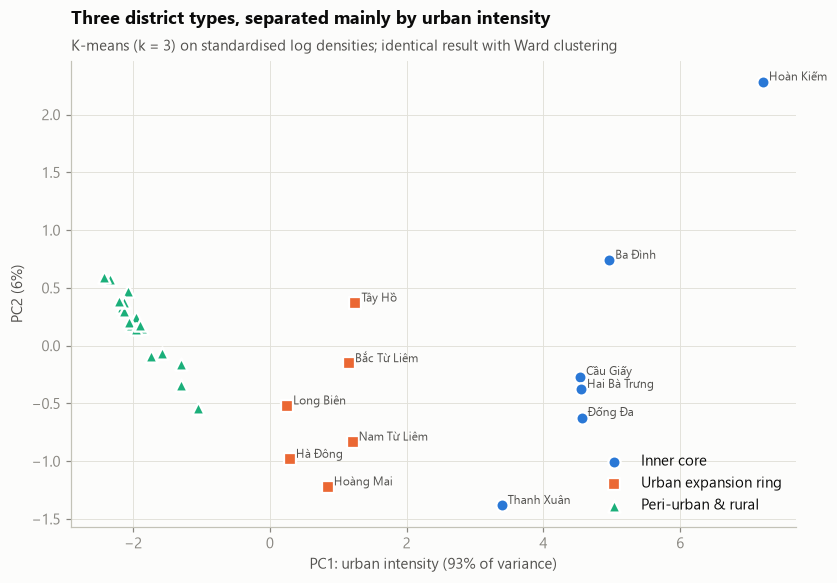

In [12]:
# Segment map in PCA space: PC1 = urban intensity, PC2 = what is left over.
P = PCA(2).fit(F)
pc = P.transform(F)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
seg_order = ["Inner core", "Urban expansion ring", "Peri-urban & rural"]
markers = ["o", "s", "^"]
for i, s in enumerate(seg_order):
    m = df.segment == s
    ax.scatter(pc[m, 0], pc[m, 1], s=64, color=SERIES[i], marker=markers[i], edgecolor="white", linewidth=1.5, label=s, zorder=3)
show = df.district_type == "urban"
label_points(ax, pc[show, 0], pc[show, 1], df.loc[show, "district"], fontsize=8)
ax.set(xlabel=f"PC1: urban intensity ({P.explained_variance_ratio_[0]:.0%} of variance)",
       ylabel=f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
ax.legend(loc="lower right")
titles(ax, "Three district types, separated mainly by urban intensity",
       "K-means (k = 3) on standardised log densities; identical result with Ward clustering")
save(fig, "fig05_segments")
plt.show()

**What the segments mean for a café brand**
- **Inner core:** highest footfall and the most cafés, but also the highest rents. Competition is fierce, yet the model
  still finds unmet demand in some districts.
- **Urban expansion ring:** large and growing residential populations at roughly half the core's land price. Demand is
  thinner per km², and Tây Hồ's lakeside café cluster makes this segment look better supplied than it is.
- **Peri-urban & rural:** the model sees a café shortfall here too, but at a median of ~1,600 residents/km² the absolute
  volume cannot support a chain outlet today. These districts are excluded at the screening stage.

## 8. Scoring the districts

**Stage 1, screen.** Keep districts with residential density ≥ 5,000/km² and a known land price. This leaves the 12 urban
districts; every rural district falls far below the threshold.

**Stage 2, score.** Three components, each standardised (z-score) across the 12 districts:

| Component | Measures | Base weight |
|---|---|---|
| Demand | Demand index (§4) | 0.35 |
| Headroom | Mean of all-café and chain-only headroom (§5) | 0.40 |
| Affordability | −log(land price) | 0.25 |

The weights are a business judgement, so instead of defending one set, §8.1 tests **10,000 random weightings**.

In [13]:
cand = df[(df.density_per_km2 >= 5000) & df.price_mvnd_m2.notna()].copy()
z = lambda s: (s - s.mean()) / s.std(ddof=0)
comp = pd.DataFrame({
    "demand": z(cand.demand_index),
    "headroom": z((z(cand.headroom) + z(cand.headroom_chain)) / 2),
    "affordability": z(-np.log(cand.price_mvnd_m2)),
}).set_index(cand.district)
BASE_W = pd.Series({"demand": 0.35, "headroom": 0.40, "affordability": 0.25})
comp["score"] = comp[BASE_W.index] @ BASE_W
comp["rank"] = comp.score.rank(ascending=False).astype(int)
print(f"{len(cand)} districts pass the screen")
comp.sort_values("rank")

12 districts pass the screen


,demand,headroom,affordability,score,rank
district,,,,,
Thanh Xuân,0.42,1.92,0.05,0.93,1
Đống Đa,0.87,0.80,-0.26,0.56,2
Ba Đình,0.95,0.45,-0.42,0.41,3
Hai Bà Trưng,0.78,0.62,-0.49,0.40,4
Cầu Giấy,0.84,0.43,-0.49,0.34,5
Hoàng Mai,-0.76,0.61,0.86,0.19,6
Nam Từ Liêm,-0.67,-0.03,0.85,-0.04,7
Bắc Từ Liêm,-0.92,-0.10,1.28,-0.04,8
Hà Đông,-1.09,-0.47,0.83,-0.36,9


### 8.1 Is the ranking robust to the weights?

Draw 10,000 weight vectors from a Dirichlet(2, 2, 2) distribution. On average this gives equal weights, and in 90 % of
draws each component's weight falls between about 6 % and 66 %. Re-rank the districts under each draw and record how often each one lands in the top 3.

In [14]:
W = RNG.dirichlet([2, 2, 2], size=10_000)
S = comp[BASE_W.index].to_numpy() @ W.T
ranks = (-S).argsort(axis=0).argsort(axis=0) + 1
robust = pd.DataFrame({
    "base rank": comp["rank"],
    "P(top 1)": (ranks == 1).mean(axis=1),
    "P(top 3)": (ranks <= 3).mean(axis=1),
    "median rank": np.median(ranks, axis=1),
    "rank 5th–95th pct": [f"{int(np.percentile(r, 5))}–{int(np.percentile(r, 95))}" for r in ranks],
}, index=comp.index).sort_values("P(top 3)", ascending=False)

# Leave-one-component-out: does any single component drive the result?
for drop in BASE_W.index:
    w = BASE_W.drop(drop) / BASE_W.drop(drop).sum()
    robust[f"rank w/o {drop}"] = (comp[w.index] @ w).rank(ascending=False).astype(int)
robust

,base rank,P(top 1),P(top 3),median rank,rank 5th–95th pct,rank w/o demand,rank w/o headroom,rank w/o affordability
district,,,,,,,,
Thanh Xuân,1,8.03e-01,9.03e-01,1.0,1–5,1,4,1
Đống Đa,2,5.41e-02,7.64e-01,2.0,1–7,4,1,2
Ba Đình,3,1.10e-03,4.17e-01,4.0,2–8,7,2,4
Hoàng Mai,6,1.00e-04,4.10e-01,6.0,2–7,2,9,7
Bắc Từ Liêm,8,1.08e-01,2.60e-01,7.0,1–9,3,6,9
Hai Bà Trưng,4,0.00e+00,1.46e-01,4.0,3–9,6,5,3
Nam Từ Liêm,7,0.00e+00,5.15e-02,7.0,3–8,5,8,8
Hoàn Kiếm,10,3.33e-02,4.35e-02,11.0,4–12,12,7,6
Cầu Giấy,5,0.00e+00,4.90e-03,6.0,4–10,8,3,5


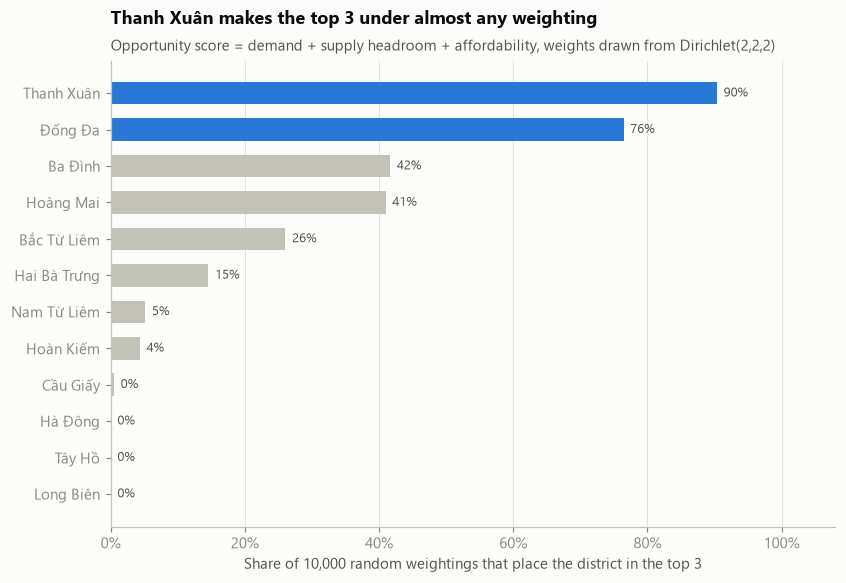

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
r = robust.sort_values("P(top 3)")
colors = [HIGHLIGHT if v >= 0.5 else CONTEXT for v in r["P(top 3)"]]
ax.barh(r.index, r["P(top 3)"], color=colors, height=0.62)
for yv, v in enumerate(r["P(top 3)"]):
    ax.text(v + 0.01, yv, f"{v:.0%}", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of 10,000 random weightings that place the district in the top 3")
top = robust.index[0]
titles(ax, f"{top} makes the top 3 under almost any weighting",
       "Opportunity score = demand + supply headroom + affordability, weights drawn from Dirichlet(2,2,2)")
save(fig, "fig06_score_robustness")
plt.show()

**What the sensitivity test says**
- **Thanh Xuân** is #1 in about 80 % of weightings and in the top 3 in about 90 %. It is dense (32k residents/km²), next to the
  office belt of Đống Đa and Cầu Giấy, has the lowest mapped café supply of any inner-core district, and sells at about 20 % below its peers.
- **Đống Đa** is the most *balanced* candidate. It is top 3 in about 76 % of weightings and becomes #1 if the headroom
  component is dropped, so it does not depend on the supply-gap estimate.
- **Hoàng Mai** is the value play. It ranks #2 when demand is ignored (large population, cheap land), but its footfall is thin.
- **Hoàn Kiếm** has the most demand but ranks near the bottom. It is saturated with cafés and costs 2.7–3.5× more per m² than the other core districts.
- **Thanh Xuân's lead rests on the headroom signal.** Without that component it falls to #4. Headroom is also the
  component most exposed to OSM under-mapping, which is why it was cross-checked with chain cafés (where Thanh Xuân is also
  the most under-supplied district) and why a field count is the first next step.

## 9. Inside the winner: which 500 m blocks to scout?

District averages hide a lot of variation. I split the 12 urban districts into 500 m × 500 m cells and fit the same kind of
supply model at cell level, using all 12 districts so the model learns what "normal" café supply looks like for a given
mix of demand drivers. Cells with the **largest shortfall of cafés** inside the top-ranked districts become the scouting list.

In [16]:
for c in ["cafe", "restaurant", "nightlife"] + DEMAND:
    if c not in grid:
        grid[c] = 0
for c in DEMAND:
    grid[f"log_{c}"] = np.log1p(grid[c])
cell_f = "cafe ~ " + " + ".join(f"log_{c}" for c in DEMAND)
cell_model = smf.negativebinomial(cell_f, grid).fit(disp=0)
grid["expected_cafe"] = cell_model.predict(grid)
grid["shortfall"] = grid.expected_cafe - grid.cafe
print(f"Cell model: {len(grid):,} cells, pseudo R² = {cell_model.prsquared:.2f}")
print(cell_model.params.round(2).to_string())

name_of = df.set_index("district").key
top_districts = robust.index[:2].tolist()
landmarks = (pois[pois.category.isin(["office", "education", "retail", "transit", "tourism"]) & pois.name.notna()]
             .assign(name=lambda d: d.name.str.strip())
             .drop_duplicates(["gx", "gy", "name"])
             .loc[lambda d: ~d.assign(n=d.name.str.lower()).duplicated(["gx", "gy", "n"])]
             .groupby(["gx", "gy"]).name.agg(lambda s: " · ".join(s.iloc[:3])))
district_of = {v: k for k, v in name_of.items()}
picks = (grid[grid.key.isin(name_of[top_districts])]
         .sort_values("shortfall", ascending=False).groupby("key").head(5)  # top 5 cells per district
         .join(landmarks, on=["gx", "gy"])
         .assign(district=lambda d: d.key.map(district_of)))
picks["block"] = picks.groupby("key").cumcount() + 1
picks = picks.assign(order=picks.district.map(top_districts.index)).sort_values(["order", "block"])
show = picks[["district", "block", "lat", "lon", "cafe", "expected_cafe", "shortfall"] + DEMAND + ["name"]]
show.rename(columns={"name": "notable demand drivers"}).style.format({"lat": "{:.4f}", "lon": "{:.4f}", "expected_cafe": "{:.1f}", "shortfall": "{:.1f}"}).hide(axis="index")

Cell model: 874 cells, pseudo R² = 0.19
Intercept       -1.73
log_office       0.58
log_education    0.13
log_tourism      0.65
log_retail       0.76
log_transit      0.22
alpha            0.96


district,block,lat,lon,cafe,expected_cafe,shortfall,office,education,tourism,retail,transit,notable demand drivers
Thanh Xuân,1,21.0031,105.8042,2,5.9,3.9,10,4,2,2,4,Phòng Công chứng số 4 thành phố Hà Nội · Goo Farm Tea Vietnam · Hà Nội Center Point
Thanh Xuân,2,20.9941,105.8042,1,3.1,2.1,7,0,1,2,4,Dịch Vụ Chuyển Phát Nasco · Công Ty TNHH May Phương Thảo · Công Ty CP TNHH Hà Linh
Thanh Xuân,3,20.9985,105.8282,1,3.0,2.0,1,1,1,7,3,Điểm cung cấp dịch vụ Viettel · Học Viện Không Quân · Bảo tàng Phòng không - Không quân
Thanh Xuân,4,20.9985,105.8234,0,1.8,1.8,1,1,0,6,4,Công Ty Cổ Phần Kỹ Thuật Số SBC · Trường Tiểu học Khương Mai · Đại Lý 169
Thanh Xuân,5,21.0076,105.8138,0,1.8,1.8,4,0,0,3,3,Thiên Đường Du Lịch - Đại lý vé máy bay · Công Ty TNHH Công Nghệ Henry Ai · Huvitz Việt Nam
Đống Đa,1,21.0301,105.8332,2,7.7,5.7,9,0,3,4,3,Trung tâm Lao động ngoài nước · Công đoàn Giáo dục Việt Nam · Nhà xuất bản Thể thao và Du lịch
Đống Đa,2,21.0165,105.8331,2,5.7,3.7,7,2,2,3,4,Vietnamobile · FPT Telecom · Deviot
Đống Đa,3,21.0256,105.8332,1,4.6,3.6,5,1,2,3,4,Viện Nghiên cứu Cơ khí · Hội Cựu Công an nhân dân phường Văn Miếu - Quốc Tử Giám · Trung tâm Phục vụ Hành chính công số 1 quận Đống Đa
Đống Đa,4,21.0075,105.8379,2,5.5,3.5,6,4,2,4,1,Tháng 12 - Weddings & Events · Trung tâm Phát triển Khoa học công nghệ và Tài năng Trẻ · Ocean Park Building
Đống Đa,5,21.0301,105.8284,3,5.9,2.9,8,3,2,2,9,Mộc Châu Milk Company · N2 Clinic Việt Nam · Công ty In Tiến Bộ


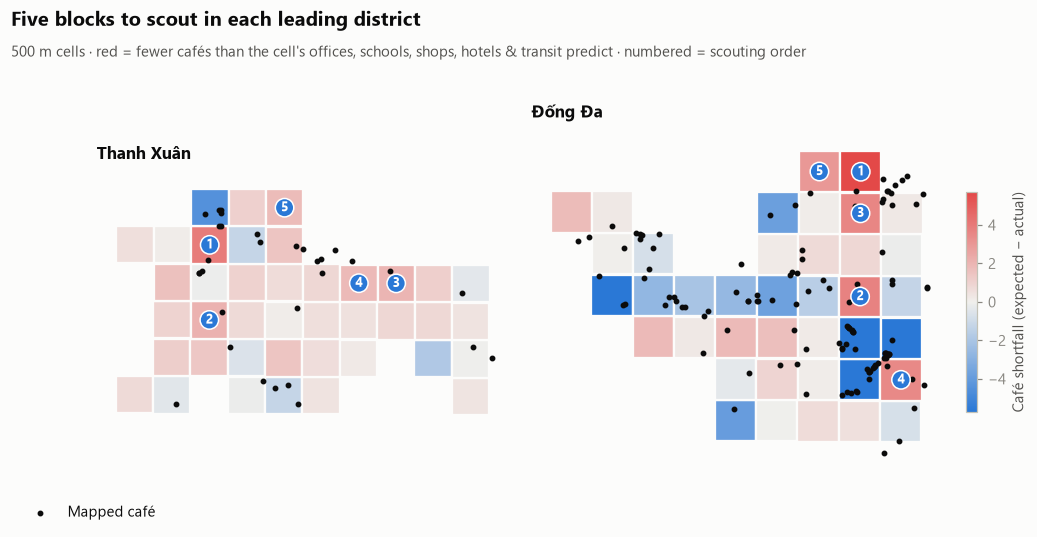

In [17]:
# Cell maps for the two leading districts: café shortfall (diverging) with mapped cafés on top.
import folium
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

DLAT = 250 / 111_320                                   # half a 500 m cell in degrees
dlon = lambda lat: 250 / (111_320 * np.cos(np.radians(lat)))
lim = np.abs(grid.loc[grid.key.isin(name_of[top_districts]), "shortfall"]).quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for ax, dname in zip(axes, top_districts):
    g = grid[grid.key == name_of[dname]]
    cafes = pois[(pois.category == "cafe") & (pois.key == name_of[dname])]
    rects = [Rectangle((lo - dlon(la), la - DLAT), 2 * dlon(la), 2 * DLAT) for lo, la in zip(g.lon, g.lat)]
    pc = PatchCollection(rects, cmap=viz.DIV, edgecolor=viz.SURFACE, linewidth=1.5)  # red = shortfall
    pc.set_array(g.shortfall.to_numpy()); pc.set_clim(-lim, lim)
    ax.add_collection(pc)
    ax.scatter(cafes.lon, cafes.lat, s=8, color="#0b0b0b", label="Mapped café", zorder=3)
    for _, r in picks[picks.district == dname].iterrows():
        ax.annotate(str(r.block), (r.lon, r.lat), ha="center", va="center", fontsize=8.5, weight="bold", color="white",
                    bbox=dict(boxstyle="circle,pad=0.22", fc=SERIES[0], ec="white"), zorder=4)
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.radians(g.lat.mean())))
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(dname, loc="left", fontsize=11)
fig.subplots_adjust(top=0.8, bottom=0.06, wspace=0.05)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower left", bbox_to_anchor=(0.06, 0.0))
cb = fig.colorbar(pc, ax=axes, shrink=0.55, pad=0.02)
cb.set_label("Café shortfall (expected − actual)", color=INK_2)
fig.suptitle("Five blocks to scout in each leading district", x=0.06, y=0.97, ha="left", fontsize=13, weight="bold")
fig.text(0.06, 0.885, "500 m cells · red = fewer cafés than the cell's offices, schools, shops, hotels & transit predict · "
         "numbered = scouting order", color=INK_2, fontsize=9.5)
save(fig, "fig07_micro_location")
plt.show()

# Interactive version of the same map.
fm = folium.Map(location=[picks.lat.mean(), picks.lon.mean()], zoom_start=14, tiles="cartodbpositron")
for _, r in grid[grid.key.isin(name_of[top_districts])].iterrows():
    folium.Rectangle(bounds=[[r.lat - DLAT, r.lon - dlon(r.lat)], [r.lat + DLAT, r.lon + dlon(r.lat)]],
                     color=None, fill=True, fill_color="#e34948" if r.shortfall > 0 else "#2a78d6",  # red = shortfall
                     fill_opacity=min(abs(r.shortfall) / lim, 1) * 0.55,
                     tooltip=f"{district_of[r.key]} · mapped cafés {int(r.cafe)} · expected {r.expected_cafe:.1f}").add_to(fm)
for _, r in pois[(pois.category == "cafe") & pois.key.isin(name_of[top_districts])].iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=2.5, color="#0b0b0b", fill=True,
                        tooltip=r["name"] if pd.notna(r["name"]) else "café").add_to(fm)
for _, r in picks.iterrows():
    folium.Marker([r.lat, r.lon], tooltip=f"{r.district} block {r.block}: shortfall {r.shortfall:.1f}").add_to(fm)
fm.save(ROOT / "reports" / "micro_location_map.html")

## 10. Recommendation

| Priority | District | Why | What would change my mind |
|---|---|---|---|
| **1. Primary** | **Thanh Xuân** | Largest supply gap in the screened set on both café measures; inner-core footfall at a lower land price | A field count showing that unmapped independents bring its café density up to the inner-core norm |
| **2. Alternative** | **Đống Đa** | Strong on every component, #1 when the supply-gap signal is removed, best value for land in the core | Ground-floor rents in the shortlisted blocks well above the district's land-price ranking |
| 3. Value option | Hoàng Mai | Biggest population (540k) and cheap land, but thin footfall per km² | Only if the brand's format is residential/neighbourhood rather than office/student |
| Avoid | Hoàn Kiếm, Tây Hồ | Saturated supply and the highest or most inflated prices | n/a |

**Go / no-go rule for the field visit.** Count every café, including independents, within each of the 5 Thanh Xuân blocks.
If the blocks still average **fewer cafés than the model's expected count**, proceed to rent negotiations in Thanh Xuân.
Otherwise switch to the Đống Đa blocks, whose case does not depend on the supply-gap estimate.

## 11. Limitations and how I would close them

| Limitation | Effect on the result | How to close it |
|---|---|---|
| OSM under-maps independent cafés outside the centre (§2.2) | Outer districts may look under-supplied | Already mitigated by the chain-only re-run; validate with a Google Places or Foursquare sample of the top cells |
| Asking prices for land, not commercial rents | Affordability is a proxy | Collect ground-floor retail rent quotes in shortlisted cells |
| 30 districts is a small sample | Wide uncertainty on district-level coefficients | The weight-sensitivity test and cell-level model (874 cells) reduce reliance on any single estimate |
| Population is a 2023-era estimate; prices are Oct 2026 | Mismatched time periods | Update when the post-reform ward census is published |
| POI counts measure *presence*, not footfall or spend | Demand is a proxy | Add mobile footfall or card-spend data if a partner can share it |
| No revenue model | Says *where*, not *how much* | Pilot with a pop-up, or benchmark sales from existing outlets in similar cells |

**Next step:** a one-day field visit to the five scouting cells to check storefront availability, foot traffic at
7–9 am and 12–2 pm, and nearby independent cafés that OSM misses.